# **트랜스포머와 LLM**


---



# **2. 트랜스포머 아키텍처**: 위치 · 블록 · 인코더-디코더
**기계학습프로그래밍 10차시 · 2교시** | 실행 환경: Google Colab CPU

| Lab | 주제 | 출처 |
|---|---|---|
| 2-1 | 어텐션은 순서를 모른다 — 순열 실험 | 위치 인코딩이 필요한 이유 |
| 2-2 | 사인·코사인 위치 인코딩 | Vaswani et al. (2017) |
| 2-3 |  RoPE: 회전으로 상대 위치를 표현 | Su et al. (2021) — LLaMA·Qwen 표준 |
| 2-4 |  트랜스포머 블록 직접 구현과 파라미터 공식 12C² | 교재 7_4 [3] |
| 2-5 |  9차시 날짜 번역기를 트랜스포머로 + 크로스 어텐션 지도 | 교재 7_4 [5][6] |

In [1]:
%pip install -q koreanize-matplotlib

In [2]:
import math, time, random, datetime, json, os
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import koreanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False
os.makedirs("figs", exist_ok=True)
def seed_all(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all(0)

---
## **2-1. 어텐션은 순서를 모른다**
입력 토큰의 순서를 섞으면 출력도 **똑같이 섞일 뿐** 값은 같다(순열 등변성). "개가 사람을 물었다" = "사람이 개를 물었다"?

In [3]:
mha = nn.MultiheadAttention(16, 2, batch_first=True)
x = torch.randn(1, 5, 16)
perm = torch.tensor([3, 0, 4, 1, 2])
y, _ = mha(x, x, x)
y_perm, _ = mha(x[:, perm], x[:, perm], x[:, perm])
print("섞은 입력의 출력 == 원래 출력을 섞은 것?", torch.allclose(y_perm, y[:, perm], atol=1e-6))
# 👉 RNN(9차시)은 순서대로 읽어서 순서를 알았지만, 어텐션은 위치 정보를 따로 넣어 줘야 한다

섞은 입력의 출력 == 원래 출력을 섞은 것? True


---
## **2-2. 사인·코사인 위치 인코딩**
$PE_{(pos,2i)} = \sin(pos/10000^{2i/d}),\quad PE_{(pos,2i+1)} = \cos(pos/10000^{2i/d})$ — 낮은 차원은 빨리, 높은 차원은 천천히 도는 '시계 바늘' 묶음

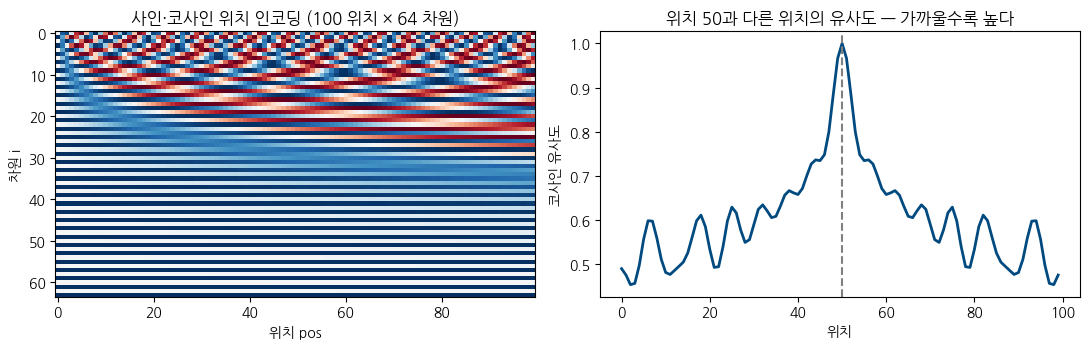

값 범위: -1.0 ~ 1.0 (위치가 커져도 −1~1 유지)


In [4]:
def sinusoidal_pe(max_len, d):
    pos = torch.arange(max_len).unsqueeze(1)
    div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
    pe = torch.zeros(max_len, d)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe

pe = sinusoidal_pe(100, 64)
sim = F.cosine_similarity(pe[50:51], pe, dim=-1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].imshow(pe.T, aspect="auto", cmap="RdBu"); axes[0].set_xlabel("위치 pos"); axes[0].set_ylabel("차원 i")
axes[0].set_title("사인·코사인 위치 인코딩 (100 위치 × 64 차원)")
axes[1].plot(sim.numpy(), color="#004A80", lw=2); axes[1].axvline(50, ls="--", c="gray")
axes[1].set_xlabel("위치"); axes[1].set_ylabel("코사인 유사도"); axes[1].set_title("위치 50과 다른 위치의 유사도 — 가까울수록 높다")
plt.tight_layout(); plt.savefig("figs/pe.png", dpi=160); plt.show()
print("값 범위:", pe.min().item(), "~", pe.max().item(), "(위치가 커져도 −1~1 유지)")

---
## **2-3. RoPE** (Rotary Position Embedding)
위치를 **더하지 않고**, q·k 벡터를 위치만큼 **회전**시킨다 → 내적이 **상대 거리(m−n)에만** 의존. LLaMA·Qwen·Gemma 등 현재 대부분의 LLM이 사용.

In [5]:
def rope(x, pos, base=10000.0):
    """x: (..., d) 짝수 차원, pos: 정수 위치. 2차원씩 묶어 각도 pos·θ_i 만큼 회전"""
    d = x.shape[-1]
    theta = base ** (-torch.arange(0, d, 2, dtype=torch.float32) / d)       # (d/2,)
    ang = pos * theta
    cos, sin = torch.cos(ang), torch.sin(ang)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.empty_like(x)
    out[..., 0::2], out[..., 1::2] = x1 * cos - x2 * sin, x1 * sin + x2 * cos
    return out

torch.manual_seed(1)
q, k = torch.randn(64), torch.randn(64)
rows = []
for m, n in [(5, 2), (105, 102), (1005, 1002), (7, 2), (507, 502)]:
    rows.append([m, n, m - n, round(float(rope(q, m) @ rope(k, n)), 4)])
rope_df = pd.DataFrame(rows, columns=["q 위치 m", "k 위치 n", "상대 거리 m−n", "q·k 점수"])
rope_df.to_csv("rope.csv", index=False)
rope_df
# 👉 거리가 같으면(3) 절대 위치가 5든 1005든 점수가 같다 — '얼마나 떨어져 있나'만 본다

,q 위치 m,k 위치 n,상대 거리 m−n,q·k 점수
0,5,2,3,-11.9893
1,105,102,3,-11.9893
2,1005,1002,3,-11.9893
3,7,2,5,-11.7954
4,507,502,5,-11.7954


---
## **2-4. 트랜스포머 블록 직접 구현** (Pre-LN, GPT-2 이후 표준)
$x \leftarrow x + \text{MHA}(\text{LN}(x)),\quad x \leftarrow x + \text{FFN}(\text{LN}(x)),\quad \text{FFN}(x) = W_2\,\text{GELU}(W_1 x)$

In [6]:
class Block(nn.Module):
    def __init__(self, C, n_heads, causal=False, dropout=0.0):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(C), nn.LayerNorm(C)
        self.attn = nn.MultiheadAttention(C, n_heads, dropout=dropout, batch_first=True)
        self.ffn = nn.Sequential(nn.Linear(C, 4 * C), nn.GELU(), nn.Linear(4 * C, C), nn.Dropout(dropout))
        self.causal = causal
    def forward(self, x):
        T = x.size(1)
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), 1) if self.causal else None
        h = self.ln1(x)
        x = x + self.attn(h, h, h, attn_mask=mask, need_weights=False)[0]   # ① 토큰끼리 정보 교환 + 잔차
        x = x + self.ffn(self.ln2(x))                                        # ② 토큰별 비선형 변환 + 잔차
        return x

rows = []
for C in [64, 768]:
    blk = Block(C, 4 if C == 64 else 12)
    ref = nn.TransformerEncoderLayer(C, 4 if C == 64 else 12, dim_feedforward=4 * C, activation="gelu", batch_first=True, norm_first=True)
    n = sum(p.numel() for p in blk.parameters())
    rows.append([C, n, 12 * C * C + 13 * C, sum(p.numel() for p in ref.parameters())])
blk_df = pd.DataFrame(rows, columns=["C (d_model)", "직접 구현 블록", "공식 12C²+13C", "nn.TransformerEncoderLayer"])
blk_df.to_csv("block_params.csv", index=False)
blk_df
# 어텐션 4C²+4C + FFN 8C²+5C + LayerNorm 2개 4C = 12C² + 13C  → C=768이면 블록 하나 약 708만 개 (GPT-2 small은 이것이 12개)

,C (d_model),직접 구현 블록,공식 12C²+13C,nn.TransformerEncoderLayer
0,64,49984,49984,49984
1,768,7087872,7087872,7087872


In [7]:
blk = Block(64, 4)
x = torch.randn(2, 10, 64)
print("입력", tuple(x.shape), "→ 출력", tuple(blk(x).shape), " (블록은 모양을 바꾸지 않는다 → 원하는 만큼 쌓을 수 있다)")

입력 (2, 10, 64) → 출력 (2, 10, 64)  (블록은 모양을 바꾸지 않는다 → 원하는 만큼 쌓을 수 있다)


---
## **2-5. 날짜 번역기를 트랜스포머로**
같은 데이터(같은 시드), 같은 에폭 수로 **GRU + Bahdanau 어텐션(9차시)** 과 비교한다.

In [8]:
MON = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MONTH = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
WD = "월화수목금토일"
def random_date():
    d = datetime.date(1950, 1, 1) + datetime.timedelta(days=random.randint(0, 36500))
    fmts = [f"{d.year}년 {d.month}월 {d.day}일",
            f"{d.year}년 {d.month}월 {d.day}일 {WD[d.weekday()]}요일",
            f"{d.year%100:02d}.{d.month:02d}.{d.day:02d}",
            f"{d.year}. {d.month}. {d.day}.",
            f"{d.day:02d}/{d.month:02d}/{d.year%100:02d}",
            f"{MON[d.month-1]} {d.day}, {d.year}",
            f"{d.day} {MONTH[d.month-1]} {d.year}",
            f"{MONTH[d.month-1].upper()} {d.day}, {d.year}",
            f"{d.year}/{d.month}/{d.day}"]
    return random.choice(fmts), d.isoformat()

seed_all(1)                                              # 9차시와 같은 시드 → 같은 3만 쌍
pairs = [random_date() for _ in range(30000)]
SRC = ["<pad>"] + sorted({c for s, _ in pairs for c in s})
TGT = ["<pad>", "<s>", "</s>"] + sorted({c for _, t in pairs for c in t})
s2i, t2i = {c: i for i, c in enumerate(SRC)}, {c: i for i, c in enumerate(TGT)}
SL = max(len(s) for s, _ in pairs)
def enc_pairs(ps):
    X = torch.zeros(len(ps), SL, dtype=torch.long); Y = torch.zeros(len(ps), 12, dtype=torch.long)
    for i, (s, t) in enumerate(ps):
        X[i, :len(s)] = torch.tensor([s2i[c] for c in s])
        Y[i] = torch.tensor([1] + [t2i[c] for c in t] + [2])
    return X, Y
Xd, Yd = enc_pairs(pairs[:27000]); Xv, Yv = enc_pairs(pairs[27000:])
print(pairs[0], "| 학습", len(Xd), "검증", len(Xv))

('1974년 2월 9일 토요일', '1974-02-09') | 학습 27000 검증 3000


In [9]:
class DateTransformer(nn.Module):
    def __init__(self, d=64, heads=4, layers=2):
        super().__init__()
        self.src_emb, self.tgt_emb = nn.Embedding(len(SRC), d, padding_idx=0), nn.Embedding(len(TGT), d)
        self.register_buffer("pe", sinusoidal_pe(32, d))
        self.tf = nn.Transformer(d_model=d, nhead=heads, num_encoder_layers=layers, num_decoder_layers=layers,
                                 dim_feedforward=4 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.out = nn.Linear(d, len(TGT))
        self.scale = math.sqrt(d)
    def forward(self, src, tgt_in):
        S, T = src.size(1), tgt_in.size(1)
        causal = nn.Transformer.generate_square_subsequent_mask(T, device=src.device)    # 디코더: 미래 금지
        h = self.tf(self.src_emb(src) * self.scale + self.pe[:S], self.tgt_emb(tgt_in) * self.scale + self.pe[:T],
                    tgt_mask=causal, src_key_padding_mask=(src == 0), memory_key_padding_mask=(src == 0))
        return self.out(h)
    @torch.no_grad()
    def translate(self, src, max_len=10):
        y = torch.ones(src.size(0), 1, dtype=torch.long, device=src.device)          # <s>
        for _ in range(max_len):                                                     # 자기회귀 생성
            nxt = self(src, y)[:, -1].argmax(-1, keepdim=True)
            y = torch.cat([y, nxt], 1)
        return y[:, 1:]

def exact_match(m, X, Y):
    m.eval(); return (m.translate(X) == Y[:, 1:11]).all(1).float().mean().item()

seed_all(0)
tfm = DateTransformer()
opt = torch.optim.AdamW(tfm.parameters(), lr=3e-3)
WARMUP = 200                                                          # 트랜스포머는 학습률 워밍업이 사실상 필수 (원 논문 4,000 스텝)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / WARMUP))
n_params = sum(p.numel() for p in tfm.parameters())
hist, sec = [], []
for ep in range(6):
    tfm.train(); perm = torch.randperm(len(Xd)); t0 = time.time()
    for i in range(0, len(Xd), 128):
        idx = perm[i:i+128]; x, y = Xd[idx], Yd[idx]
        logits = tfm(x, y[:, :-1])                                    # 교사 강요: 정답을 한 칸 밀어 입력
        loss = F.cross_entropy(logits.reshape(-1, len(TGT)), y[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(tfm.parameters(), 1.0); opt.step(); sched.step()
    sec.append(time.time() - t0); hist.append(exact_match(tfm, Xv, Yv))
    print(f"epoch {ep+1}: 완전 일치 {hist[-1]:.3f}  ({sec[-1]:.0f}s)")
print("파라미터 수:", f"{n_params:,}")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(


epoch 1: 완전 일치 0.069  (33s)
epoch 2: 완전 일치 0.291  (33s)
epoch 3: 완전 일치 0.601  (33s)
epoch 4: 완전 일치 0.709  (33s)
epoch 5: 완전 일치 0.794  (33s)
epoch 6: 완전 일치 0.874  (33s)
파라미터 수: 239,566


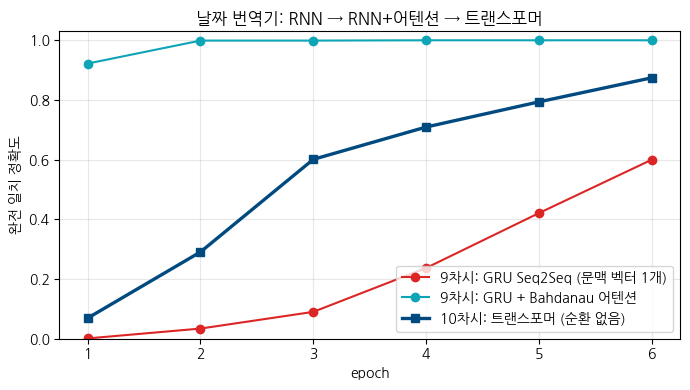

In [10]:
# 9차시 결과 (_09_ml_4 실행 결과, 같은 데이터·같은 6 에폭)
prev = {"plain": [0.001, 0.034, 0.090, 0.237, 0.421, 0.600], "attn": [0.922, 0.999, 0.999, 1.0, 1.0, 1.0]}
if os.path.exists("s2s_results.json"):
    prev = json.load(open("s2s_results.json"))
plt.figure(figsize=(7, 4))
plt.plot(range(1, 7), prev["plain"], "o-", c="#DC2626", label="9차시: GRU Seq2Seq (문맥 벡터 1개)")
plt.plot(range(1, 7), prev["attn"], "o-", c="#0EA5B7", label="9차시: GRU + Bahdanau 어텐션")
plt.plot(range(1, 7), hist, "s-", c="#004A80", lw=2.4, label="10차시: 트랜스포머 (순환 없음)")
plt.ylim(0, 1.03); plt.xlabel("epoch"); plt.ylabel("완전 일치 정확도"); plt.legend(); plt.grid(alpha=.3)
plt.title("날짜 번역기: RNN → RNN+어텐션 → 트랜스포머"); plt.tight_layout(); plt.savefig("figs/date_compare.png", dpi=160); plt.show()
json.dump({"transformer": hist, "sec": sec, "params": n_params}, open("date_tf.json", "w"))

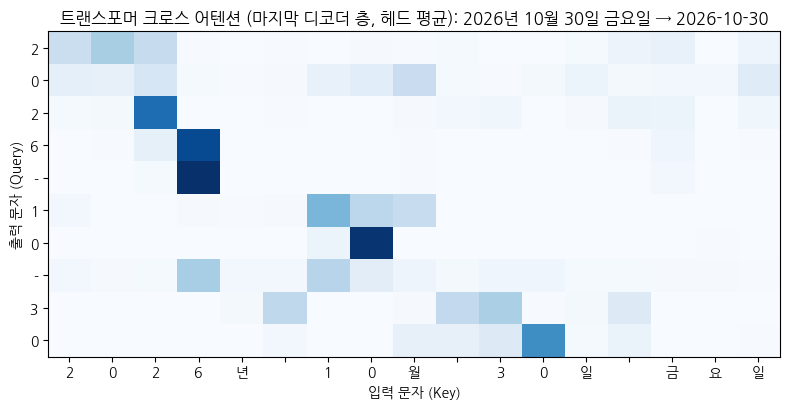

In [11]:
# 크로스 어텐션 지도: 디코더 마지막 층이 인코더 출력(입력 문자)의 어디를 보는가
captured = {}
layer = tfm.tf.decoder.layers[-1]
def hook(mod, args, kwargs, out):
    captured["q"], captured["k"] = args[0], args[1]
    captured["kpm"] = kwargs.get("key_padding_mask")
hd = layer.multihead_attn.register_forward_hook(hook, with_kwargs=True)

s = "2026년 10월 30일 금요일"
src = torch.tensor([[s2i[c] for c in s] + [0] * (SL - len(s))])
tfm.eval()
pred = tfm.translate(src)
with torch.no_grad():
    tfm(src, torch.cat([torch.ones(1, 1, dtype=torch.long), pred[:, :-1]], 1))
    _, W = layer.multihead_attn(captured["q"], captured["k"], captured["k"], key_padding_mask=captured["kpm"],
                                need_weights=True, average_attn_weights=True)
hd.remove()
out_txt = "".join(TGT[i] for i in pred[0].tolist())
plt.figure(figsize=(8, 4.2))
plt.imshow(W[0, :, :len(s)].numpy(), cmap="Blues", aspect="auto")
plt.xticks(range(len(s)), list(s)); plt.yticks(range(10), list(out_txt))
plt.xlabel("입력 문자 (Key)"); plt.ylabel("출력 문자 (Query)"); plt.title(f"트랜스포머 크로스 어텐션 (마지막 디코더 층, 헤드 평균): {s} → {out_txt}")
plt.tight_layout(); plt.savefig("figs/date_cross_attn.png", dpi=160); plt.show()

**관찰**: 같은 6 에폭에서 트랜스포머는 GRU+어텐션보다 느리게 배운다. 작은 데이터·짧은 학습에서는 '순서대로 읽는' RNN의 귀납적 편향이 유리하다.
트랜스포머의 진짜 강점은 **병렬 학습 → 대규모 데이터·모델로 확장**할 때 나타난다 (스케일링 법칙).
**🎯 미션**: 에폭을 12로 늘리거나 WARMUP을 바꿔 100%에 도달하는 데 필요한 에폭을 비교해 보자.

## **정리**
| 부품 | 역할 | 최신 LLM에서는 |
|---|---|---|
| 위치 인코딩 | 순서를 모르는 어텐션에 위치 정보 주입 | 사인·코사인 → **RoPE** |
| 멀티헤드 어텐션 | 토큰 간 정보 교환 | **GQA**(KV 헤드 공유) |
| FFN | 토큰별 비선형 변환 (파라미터의 2/3) | **SwiGLU** |
| 잔차 + LayerNorm | 깊게 쌓아도 학습 안정 | **Pre-Norm + RMSNorm** |
| 인코더 / 디코더 / 크로스 어텐션 | 이해 / 생성 / 입력 참조 | 생성 LLM은 **디코더만** (3교시) |